# Multivariate regression of charging point density

This notebook answers the main research question: which characteristics explain the most variation in public charging points per 1,000 households, when all are considered together?

**Input:** `data/processed/all_variables_per_municipality.csv`, created by notebook 6.

**Approach**
1. Select one variable from each pair of strongly correlated variables (|r| ≥ 0.66 in notebook 6), to avoid multicollinearity.
2. Estimate an ordinary least squares (OLS) regression on standardised variables, so that the coefficients (β) can be compared directly.
3. Use heteroskedasticity-robust standard errors (HC3), because the spread of the residuals may differ between small and large municipalities.
4. Check multicollinearity with variance inflation factors (VIF) and inspect the residuals.
5. Test two alternative models as robustness checks.

**Outputs:** `data/processed/regression_results.csv`, `figures/figure_regression_coefficients.png`, `figures/figure_regression_residuals.png`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

PROCESSED = "../data/processed/"
FIGURES = "../figures/"

## 1. Load the data

We give the columns short English names, so the regression formulas below are easy to read. Population density is strongly right-skewed (a few cities are far denser than the rest), so we use its natural logarithm: in notebook 6 this gave a stronger and more linear relation with charging point density (r = 0.48 instead of 0.41).

In [2]:
df = pd.read_csv(PROCESSED + "all_variables_per_municipality.csv")

df = df.rename(columns={
    "gemeente": "municipality",
    "laadpunten_per_1000_huishoudens": "charging",
    "med_gestandaardiseerd_inkomen_keur": "income",
    "hoogopgeleid_pct": "education",
    "ouderen_65plus_pct": "age65",
    "meergezinswoning_pct": "apartments",
})
df["log_density"] = np.log(df["bevolkingsdichtheid"])

# Readable names for tables and figures
LABELS = {
    "income": "Median standardised income",
    "education": "Highly educated (%)",
    "age65": "Residents 65+ (%)",
    "log_density": "Population density (log)",
    "apartments": "Apartments (% of dwellings)",
}

print("Municipalities:", len(df))

Municipalities: 342


## 2. Prepare the data: complete cases and z-scores

Median income is missing for three small municipalities (CBS does not publish it), so these are left out. All three models then use the same municipalities.

Next, every variable is converted to a z-score: (value − mean) / standard deviation. After this step all variables have mean 0 and standard deviation 1, so the coefficients of income (in k€), density (log) and age (in %) can be compared directly.

In [3]:
columns = ["charging"] + list(LABELS)
data = df[["municipality"] + columns].dropna()
print("Municipalities used:", len(data))

z = data.copy()
for col in columns:
    z[col] = (data[col] - data[col].mean()) / data[col].std()

z[columns].describe().round(2)

Municipalities used: 339


,charging,income,education,age65,log_density,apartments
count,339.00,339.00,339.00,339.00,339.00,339.00
mean,-0.00,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.14,-2.85,-2.24,-3.43,-2.23,-1.28
25%,-0.72,-0.62,-0.66,-0.62,-0.75,-0.68
50%,-0.22,-0.03,-0.22,0.00,-0.12,-0.30
75%,0.63,0.59,0.38,0.62,0.77,0.46
max,4.12,3.88,3.51,3.08,2.49,4.77


## 3. Choice of variables and the three models

Notebook 6 showed four pairs of strongly correlated variables. From each pair one variable is kept:

| Pair (r) | Kept | Reason |
| --- | --- | --- |
| Under 25 and 65+ (−0.82) | 65+ | Slightly stronger link with charging point density |
| Mean and median income (0.66) | Median | Not distorted by a few very rich municipalities |
| Population density and apartments (0.79) | Density (log) | Strongest single factor; apartments are tested in model 2 |
| Left-wing vote share and education (0.78) | Education | Both largely measure the same thing; left-wing vote share is not used in the regression |

- **Model 1 (main):** median income, education, 65+ and population density.
- **Model 2 (apartments):** share of apartments instead of population density, as a second indicator of need.
- **Model 3 (no outliers):** the main model without Loon op Zand and Sluis. These municipalities have far more charging points than the model predicts (residual of about 4 SD, see section 7), probably because of tourism. This model tests whether these two municipalities drive the results.

Each model is estimated with OLS. `cov_type="HC3"` gives robust standard errors.

In [4]:
MODELS = {
    "Model 1 (main)":        "charging ~ income + education + age65 + log_density",
    "Model 2 (apartments)":  "charging ~ income + education + age65 + apartments",
    "Model 3 (no outliers)": "charging ~ income + education + age65 + log_density",
}

OUTLIERS = ["Loon op Zand", "Sluis"]

results = {}
for name, formula in MODELS.items():
    if name == "Model 3 (no outliers)":
        sample = z[~z["municipality"].isin(OUTLIERS)]
    else:
        sample = z
    results[name] = smf.ols(formula, data=sample).fit(cov_type="HC3")
    print(name, "  adjusted R² =", round(results[name].rsquared_adj, 3), "  N =", int(results[name].nobs))

Model 1 (main)   adjusted R² = 0.354   N = 339
Model 2 (apartments)   adjusted R² = 0.342   N = 339
Model 3 (no outliers)   adjusted R² = 0.411   N = 337


## 4. Multicollinearity check (VIF)

The variance inflation factor (VIF) shows how much a variable overlaps with the other variables in the same model. A VIF below 5 means multicollinearity is not a problem.

In [5]:
def calculate_vif(predictors):
    """Return the VIF of each predictor in a model with these predictors."""
    X = sm.add_constant(z[predictors])
    vif = {}
    for i, name in enumerate(predictors, start=1):   # position 0 is the constant
        vif[name] = variance_inflation_factor(X.values, i)
    return vif


vifs = {}
for name, model in results.items():
    predictors = list(model.params.index.drop("Intercept"))
    vifs[name] = calculate_vif(predictors)
    print(name, {LABELS[v]: round(float(value), 2) for v, value in vifs[name].items()})

Model 1 (main) {'Median standardised income': 1.51, 'Highly educated (%)': 1.84, 'Residents 65+ (%)': 1.33, 'Population density (log)': 1.68}
Model 2 (apartments) {'Median standardised income': 2.34, 'Highly educated (%)': 2.77, 'Residents 65+ (%)': 1.35, 'Apartments (% of dwellings)': 2.52}
Model 3 (no outliers) {'Median standardised income': 1.51, 'Highly educated (%)': 1.84, 'Residents 65+ (%)': 1.33, 'Population density (log)': 1.68}


## 5. Results of the main model

For each variable: the standardised coefficient β, its 95% confidence interval, the p-value and the VIF. β is the change in charging point density, in standard deviations, when that variable increases by one standard deviation and the others stay the same.

In [6]:
model = results["Model 1 (main)"]
ci = model.conf_int()   # columns 0 (low) and 1 (high)

rows = []
for var in model.params.index.drop("Intercept"):
    rows.append({
        "Variable": LABELS[var],
        "β (standardised)": model.params[var],
        "95% CI low": ci.loc[var, 0],
        "95% CI high": ci.loc[var, 1],
        "p-value": model.pvalues[var],
        "VIF": vifs["Model 1 (main)"][var],
    })
main = pd.DataFrame(rows).set_index("Variable")

print(f"N = {int(model.nobs)},  R² = {model.rsquared:.3f},  adjusted R² = {model.rsquared_adj:.3f}")
main.round(3)

N = 339,  R² = 0.362,  adjusted R² = 0.354


,β (standardised),95% CI low,95% CI high,p-value,VIF
Variable,,,,,
Median standardised income,0.372,0.265,0.479,0.000,1.512
Highly educated (%),-0.085,-0.211,0.042,0.190,1.840
Residents 65+ (%),-0.129,-0.232,-0.025,0.015,1.327
Population density (log),0.451,0.344,0.558,0.000,1.678


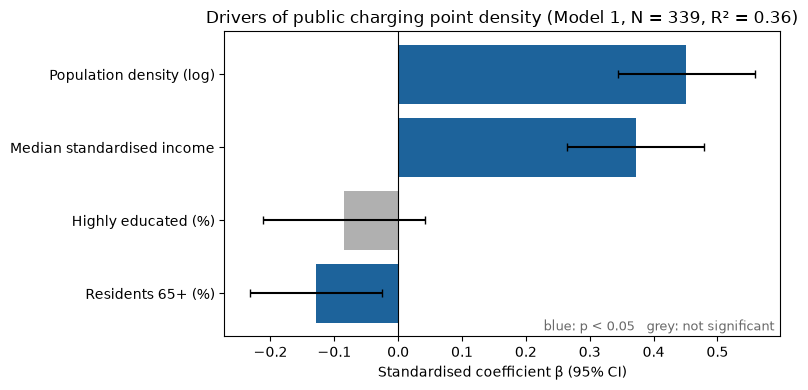

In [7]:
# Figure: standardised coefficients with 95% confidence intervals
plot = main.sort_values("β (standardised)")
error_low = plot["β (standardised)"] - plot["95% CI low"]
error_high = plot["95% CI high"] - plot["β (standardised)"]

colors = []
for p in plot["p-value"]:
    if p < 0.05:
        colors.append("#1d639b")   # significant
    else:
        colors.append("#b0b0b0")   # not significant

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(plot.index, plot["β (standardised)"], color=colors,
        xerr=[error_low, error_high], capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardised coefficient β (95% CI)")
ax.set_title(f"Drivers of public charging point density (Model 1, N = {int(model.nobs)}, R² = {model.rsquared:.2f})")
ax.text(0.99, 0.02, "blue: p < 0.05   grey: not significant", transform=ax.transAxes,
        ha="right", fontsize=9, color="dimgray")
plt.tight_layout()
plt.savefig(FIGURES + "figure_regression_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Comparison of the three models

If a coefficient keeps its sign and significance across the models, the result does not depend on the exact choice of variables.

In [8]:
rows = []
for name, m in results.items():
    for var in m.params.index.drop("Intercept"):
        rows.append({"Model": name, "Variable": LABELS[var], "β": m.params[var],
                     "p-value": m.pvalues[var], "VIF": vifs[name][var]})
    rows.append({"Model": name, "Variable": "R² (adjusted)", "β": m.rsquared_adj})
    rows.append({"Model": name, "Variable": "N", "β": m.nobs})

comparison = pd.DataFrame(rows)
comparison.to_csv(PROCESSED + "regression_results.csv", index=False)

# One column per model: β and p-value side by side
beta_table = comparison.pivot(index="Variable", columns="Model", values="β")
p_table = comparison.pivot(index="Variable", columns="Model", values="p-value")
order = list(LABELS.values()) + ["R² (adjusted)", "N"]
beta_table.loc[order].round(3)

Model,Model 1 (main),Model 2 (apartments),Model 3 (no outliers)
Variable,,,
Median standardised income,0.372,0.578,0.377
Highly educated (%),-0.085,-0.243,-0.077
Residents 65+ (%),-0.129,-0.132,-0.149
Population density (log),0.451,NaN,0.462
Apartments (% of dwellings),NaN,0.525,NaN
R² (adjusted),0.354,0.342,0.411
N,339.000,339.000,337.000


In [9]:
# p-values per model (empty = variable not in that model)
p_table.loc[list(LABELS.values())].round(4)

Model,Model 1 (main),Model 2 (apartments),Model 3 (no outliers)
Variable,,,
Median standardised income,0.0000,0.0000,0.0000
Highly educated (%),0.1900,0.0019,0.2136
Residents 65+ (%),0.0152,0.0156,0.0033
Population density (log),0.0000,NaN,0.0000
Apartments (% of dwellings),NaN,0.0000,NaN


## 7. Residual diagnostics

OLS assumes that the residuals (actual minus predicted value) show no pattern against the fitted values and are roughly normally distributed. The left plot checks the first assumption, the right plot (Q-Q plot) the second: if the residuals are normal, the points lie on the line.

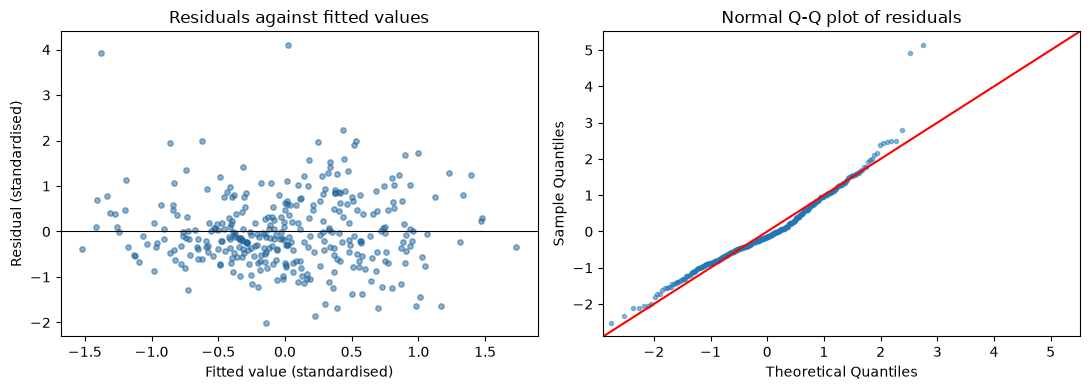

In [10]:
model = results["Model 1 (main)"]
residuals = model.resid
fitted = model.fittedvalues

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.scatter(fitted, residuals, alpha=0.5, s=15, color="#1d639b")
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_xlabel("Fitted value (standardised)")
ax1.set_ylabel("Residual (standardised)")
ax1.set_title("Residuals against fitted values")

sm.qqplot(residuals, line="45", fit=True, ax=ax2, markersize=3, alpha=0.5)
ax2.set_title("Normal Q-Q plot of residuals")

plt.tight_layout()
plt.savefig(FIGURES + "figure_regression_residuals.png", dpi=200, bbox_inches="tight")
plt.show()

The municipalities with the largest residuals have far more (positive) or far fewer (negative) charging points than the model predicts.

In [11]:
data["residual"] = model.resid

largest = data.sort_values("residual", ascending=False)
outliers = pd.concat([largest.head(5), largest.tail(5)])
outliers[["municipality", "residual", "charging"]].rename(columns={
    "residual": "Residual (SD)",
    "charging": "Charging points per 1,000 households",
}).round(2)

,municipality,Residual (SD),"Charging points per 1,000 households"
169,Loon op Zand,4.10,42.88
255,Sluis,3.93,32.23
57,Culemborg,2.23,33.05
182,Midden-Delfland,1.98,32.03
289,Veere,1.98,24.23
110,Haarlem,-1.64,11.85
51,Bunschoten,-1.68,8.41
335,Zoeterwoude,-1.68,6.34
322,Wijk bij Duurstede,-1.85,4.04
231,Renkum,-2.00,0.54
